# Telco Customer Churn — análise estatística e classificação

**Disciplina:** Introdução à Ciência de Dados — ICMC/USP  
**Professor:** Francisco Rodrigues  
**Atividade:** Telco Customer Churn  
**Base:** IBM/Telco Customer Churn (7.043 clientes; 21 colunas).

**Objetivos:** explorar os fatores associados ao cancelamento, comparar classificadores e estratégias de balanceamento, avaliar um modelo final sem vazamento de dados e discutir hipóteses de retenção sem confundir associação com causalidade.

> **Protocolo metodológico.** Primeiro, o conjunto de teste é reservado com amostragem estratificada (20%). As análises exploratórias associadas à seleção/engenharia de atributos, os testes estatísticos, a validação cruzada e a reamostragem são realizados **somente nos 80% de treinamento**. O teste é acessado apenas na seção final de avaliação. A auditoria descritiva inicial do arquivo bruto é usada exclusivamente para validar o esquema e o formato dos dados.

**Reprodução:** execute **Ambiente de execução → Executar tudo** no Google Colab com o CSV `WA_Fn-UseC_-Telco-Customer-Churn.csv` carregado. O notebook também funciona localmente, com CSV na mesma pasta. Para a etapa de balanceamento utiliza-se `imbalanced-learn`.

## 1. Bibliotecas, leitura e integridade da base

In [1]:
# Em Colab, descomente apenas se a biblioteca não estiver disponível:
# %pip install -q imbalanced-learn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 40)
SEED = 42
ALPHA = 0.05
COL_NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
COL_CAT_BASE = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
                "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                "Contract", "PaperlessBilling", "PaymentMethod"]
SERVICOS_INTERNET = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                     "TechSupport", "StreamingTV", "StreamingMovies"]
print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


In [2]:
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    encontrados = list(Path.cwd().glob("*Telco*Churn*.csv"))
    if encontrados:
        DATA_PATH = encontrados[0]
    else:
        try:
            from google.colab import files
            enviados = files.upload()
            if not enviados:
                raise FileNotFoundError("Nenhum CSV foi fornecido.")
            DATA_PATH = Path(next(iter(enviados)))
        except ImportError as exc:
            raise FileNotFoundError("Coloque o CSV na pasta do notebook.") from exc

df_raw = pd.read_csv(DATA_PATH)
esperadas = set(COL_CAT_BASE + COL_NUM + ["customerID", "Churn"])
assert esperadas.issubset(df_raw.columns), "Arquivo não contém todas as colunas esperadas."
assert df_raw["Churn"].isin(["Yes", "No"]).all(), "Rótulos inesperados em Churn."
print("Arquivo:", DATA_PATH.name)
print("Dimensões:", df_raw.shape)
print("Duplicatas de linhas:", int(df_raw.duplicated().sum()))
print("Duplicatas de customerID:", int(df_raw.customerID.duplicated().sum()))
print("Campos em branco em TotalCharges:", int(df_raw.TotalCharges.astype(str).str.strip().eq("").sum()))
print("Valores nulos originais:", int(df_raw.isna().sum().sum()))
display(df_raw.head(3))

Arquivo: WA_Fn-UseC_-Telco-Customer-Churn.csv
Dimensões: (7043, 21)
Duplicatas de linhas: 0
Duplicatas de customerID: 0
Campos em branco em TotalCharges: 11
Valores nulos originais: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


### 1.1. Qualidade, inconsistências e conversão de `TotalCharges`

`TotalCharges` é lida como texto porque 11 registros contêm espaços em branco. A conversão com `errors="coerce"` transforma esses registros em `NaN`. `customerID` é um identificador único, e não um atributo explicativo apropriado; incluí-lo poderia induzir padrões espúrios. `SeniorCitizen` é uma categoria binária codificada como 0/1. As categorias `No internet service` e `No phone service` são **estados estruturais válidos**, e não valores ausentes.

In [3]:
# Auditoria somente de integridade/estrutura; não ajustar nenhum transformador aqui.
df_base = df_raw.copy()
df_base["TotalCharges"] = pd.to_numeric(df_base["TotalCharges"], errors="coerce")
display(pd.DataFrame({"tipo": df_base.dtypes.astype(str),
                      "ausentes": df_base.isna().sum(),
                      "distintos": df_base.nunique(dropna=True)}))
sem_total = df_base[df_base.TotalCharges.isna()]
print("TotalCharges ausente:", len(sem_total),
      "| Todos tenure=0:", sem_total.tenure.eq(0).all())
print("Inconsistências entre InternetService=No e serviços opcionais:",
      int((df_base.loc[df_base.InternetService.eq('No'), SERVICOS_INTERNET]
           != 'No internet service').sum().sum()))
print("Inconsistências PhoneService / MultipleLines:",
      int((df_base.loc[df_base.PhoneService.eq('No'), 'MultipleLines']
           != 'No phone service').sum()))

,tipo,ausentes,distintos
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


TotalCharges ausente: 11 | Todos tenure=0: True
Inconsistências entre InternetService=No e serviços opcionais: 0
Inconsistências PhoneService / MultipleLines: 0


## 2. Separação estratificada — isolamento do teste

In [4]:
X = df_base.drop(columns=["customerID", "Churn"])
y = df_base["Churn"].map({"No":0, "Yes":1}).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert X_train.index.intersection(X_test.index).empty
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Distribuição de Churn (arquivo / treino / teste):")
display(pd.DataFrame({
    "Base completa": y.value_counts(normalize=True).sort_index(),
    "Treino": y_train.value_counts(normalize=True).sort_index(),
    "Teste (somente distribuição)": y_test.value_counts(normalize=True).sort_index()
}).rename(index={0:"Não cancela",1:"Cancela"}).mul(100).round(2))
# A partir daqui até a seção de avaliação final, NÃO utilizar X_test/y_test.
eda = X_train.copy()
eda["Churn"] = y_train.map({0:"No",1:"Yes"})
print("TotalCharges ausente apenas no treino:", int(eda.TotalCharges.isna().sum()))

Treino: (5634, 19) | Teste: (1409, 19)
Distribuição de Churn (arquivo / treino / teste):


,Base completa,Treino,Teste (somente distribuição)
Churn,,,
Não cancela,73.46,73.46,73.46
Cancela,26.54,26.54,26.54


TotalCharges ausente apenas no treino: 8


**Tratamento dos ausentes durante a modelagem:** para `TotalCharges`, será aplicada uma imputação constante de zero, coerente com o fato de os valores vazios ocorrerem em registros com `tenure = 0`. A imputação e a padronização estarão **dentro do pipeline**, sendo reajustadas em cada fold da validação cruzada. Isso é mais seguro e reprodutível do que modificar previamente `X_train` e `X_test`.

## 3. Análise exploratória (somente treinamento)

,Clientes,Proporção (%)
Churn,,
No,4139,73.46
Yes,1495,26.54


Acurácia do classificador trivial (sempre No): 0.7346


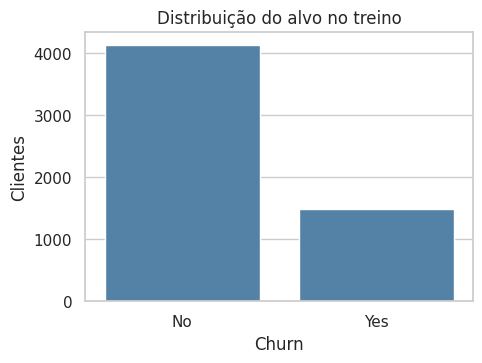

In [5]:
contagem_churn = eda.Churn.value_counts().reindex(["No","Yes"])
frequencia_churn = pd.DataFrame({"Clientes":contagem_churn,
                                "Proporção (%)":100*contagem_churn/len(eda)})
display(frequencia_churn.round(2))
print("Acurácia do classificador trivial (sempre No):", round((y_train==0).mean(),4))
fig, ax = plt.subplots(figsize=(5,3.5))
sns.barplot(x=frequencia_churn.index,y=frequencia_churn["Clientes"],ax=ax,color="steelblue")
ax.set(title="Distribuição do alvo no treino",xlabel="Churn",ylabel="Clientes")
plt.show()

### 3.1. Permanência, cobrança mensal e valor acumulado

tenure                      MonthlyCharges                       \
       count   mean median    std          count   mean median    std   
Churn                                                                   
No      4139  37.59   38.0  24.14           4139  61.34  64.40  31.14   
Yes     1495  18.36   10.0  19.74           1495  74.86  79.95  24.60   

      TotalCharges                            
             count     mean  median      std  
Churn                                         
No            4131  2569.69  1691.9  2342.74  
Yes           1495  1564.59   740.3  1908.84

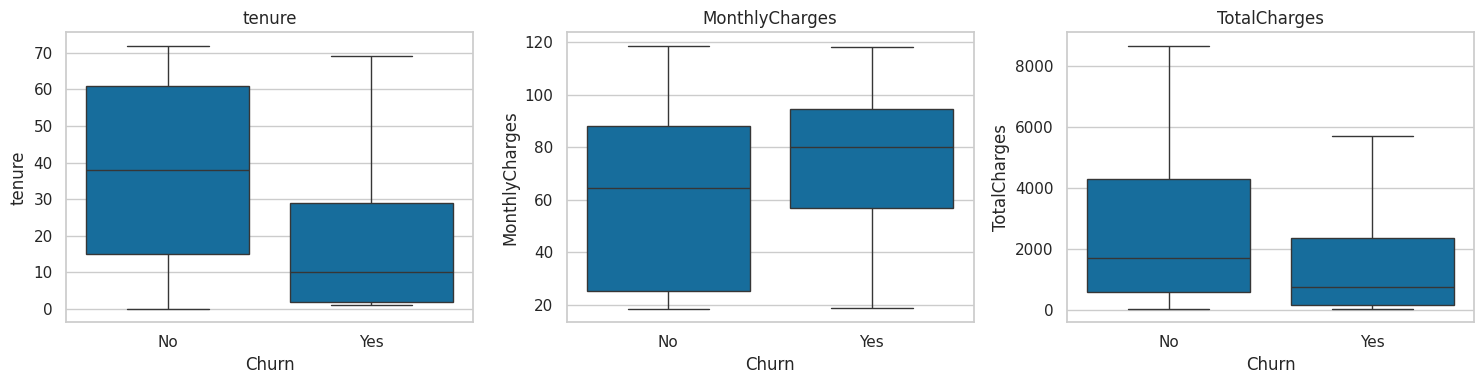

Churn,No,Yes,Total,Taxa_Churn_%
GrupoTenure,,,,
Até 10 meses,790,765,1555,49.2
Mais de 10 meses,3349,730,4079,17.9


In [6]:
resumo_num = eda.groupby("Churn")[COL_NUM].agg(["count","mean","median","std"])
display(resumo_num.round(2))
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,variavel in zip(axes,COL_NUM):
    sns.boxplot(data=eda,x="Churn",y=variavel,ax=ax,showfliers=False)
    ax.set_title(variavel)
plt.tight_layout(); plt.show()

def taxa_categoria(dados, variavel):
    tab = pd.crosstab(dados[variavel], dados.Churn).reindex(columns=["No","Yes"],fill_value=0)
    tab["Total"] = tab.sum(axis=1)
    tab["Taxa_Churn_%"] = (100*tab["Yes"]/tab["Total"]).round(2)
    return tab

grupos_tenure = pd.cut(eda.tenure,bins=[-1,10,np.inf],labels=["Até 10 meses","Mais de 10 meses"])
display(taxa_categoria(eda.assign(GrupoTenure=grupos_tenure),"GrupoTenure"))

**Leitura:** compare médias **e medianas** entre as classes e observe o tamanho dos grupos. O ponto de corte de dez meses é apenas descritivo. `TotalCharges` é um acumulado: sua associação com o churn mistura informação sobre tempo e cobrança, logo não deve ser interpretada isoladamente como efeito do preço.

### 3.2. Contratos, pagamentos, serviços e características demográficas


 Contract


Churn,No,Yes,Total,Taxa_Churn_%
Contract,,,,
Month-to-month,1776,1326,3102,42.75
One year,1043,130,1173,11.08
Two year,1320,39,1359,2.87



 PaymentMethod


Churn,No,Yes,Total,Taxa_Churn_%
PaymentMethod,,,,
Bank transfer (automatic),1043,201,1244,16.16
Credit card (automatic),1032,181,1213,14.92
Electronic check,1026,865,1891,45.74
Mailed check,1038,248,1286,19.28



 InternetService


Churn,No,Yes,Total,Taxa_Churn_%
InternetService,,,,
DSL,1575,362,1937,18.69
Fiber optic,1438,1045,2483,42.09
No,1126,88,1214,7.25


... (2 outputs left out)


 TechSupport


Churn,No,Yes,Total,Taxa_Churn_%
TechSupport,,,,
No,1614,1157,2771,41.75
No internet service,1126,88,1214,7.25
Yes,1399,250,1649,15.16



 PaperlessBilling


Churn,No,Yes,Total,Taxa_Churn_%
PaperlessBilling,,,,
No,1934,369,2303,16.02
Yes,2205,1126,3331,33.80


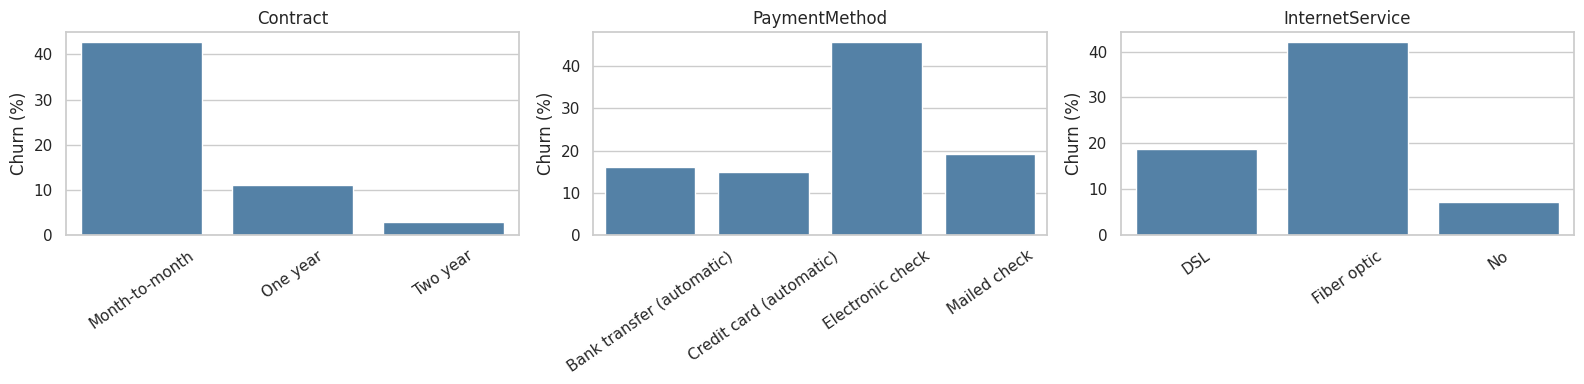

In [7]:
principais = ["Contract","PaymentMethod","InternetService","OnlineSecurity",
              "TechSupport","PaperlessBilling"]
for variavel in principais:
    print("\n",variavel)
    display(taxa_categoria(eda,variavel))
fig, axes = plt.subplots(1,3,figsize=(16,4))
for ax,variavel in zip(axes,["Contract","PaymentMethod","InternetService"]):
    tab = taxa_categoria(eda,variavel).reset_index()
    sns.barplot(data=tab,x=variavel,y="Taxa_Churn_%",color="steelblue",ax=ax)
    ax.tick_params(axis="x",rotation=35)
    ax.set(xlabel="",ylabel="Churn (%)",title=variavel)
plt.tight_layout(); plt.show()

In [8]:
# Exibe TODAS as categorias, sempre com o tamanho dos grupos.
linhas=[]
for variavel in COL_CAT_BASE:
    for cat,linha in taxa_categoria(eda,variavel).iterrows():
        linhas.append({"Variável":variavel,"Categoria":cat,
                       "Clientes":int(linha["Total"]),
                       "Cancelamentos":int(linha["Yes"]),
                       "Taxa de churn (%)":float(linha["Taxa_Churn_%"])})
tabela_categorias = pd.DataFrame(linhas)
display(tabela_categorias)

,Variável,Categoria,Clientes,Cancelamentos,Taxa de churn (%)
0,gender,Female,2801,746,26.63
1,gender,Male,2833,749,26.44
2,SeniorCitizen,0,4714,1117,23.70
3,SeniorCitizen,1,920,378,41.09
4,Partner,No,2905,952,32.77
5,Partner,Yes,2729,543,19.90
6,Dependents,No,3955,1240,31.35
7,Dependents,Yes,1679,255,15.19
8,PhoneService,No,559,135,24.15
9,PhoneService,Yes,5075,1360,26.80


**Cuidados:** a categoria `No internet service` não deve ser comparada como se significasse ausência voluntária de um serviço adicional. Categorias sobrepostas não representam populações independentes. As proporções são associações descritivas, não evidências de efeitos causais.

## 4. Testes estatísticos e tamanho das associações (treinamento)

In [9]:
resultados_num=[]
for variavel in COL_NUM:
    no=eda.loc[eda.Churn.eq('No'),variavel].dropna()
    yes=eda.loc[eda.Churn.eq('Yes'),variavel].dropna()
    welch=ttest_ind(no,yes,equal_var=False)
    mw=mannwhitneyu(no,yes,alternative='two-sided')
    resultados_num.append({"Variável":variavel,"n_No":len(no),"n_Yes":len(yes),
                           "Média_No":no.mean(),"Média_Yes":yes.mean(),
                           "t de Welch":welch.statistic,"p_Welch":welch.pvalue,
                           "U_Mann-Whitney":mw.statistic,"p_Mann-Whitney":mw.pvalue})
tabela_testes_num=pd.DataFrame(resultados_num)
exibir_num=tabela_testes_num.copy()
for c in ['p_Welch','p_Mann-Whitney']:
    exibir_num[c]=exibir_num[c].map(lambda valor:f'{valor:.2e}')
display(exibir_num.round(3))

,Variável,n_No,n_Yes,Média_No,Média_Yes,t de Welch,p_Welch,U_Mann-Whitney,p_Mann-Whitney
0,tenure,4139,1495,37.588,18.359,30.350,4.44e-178,4549249.0,1.07e-160
1,MonthlyCharges,4139,1495,61.343,74.860,-16.908,1.39e-61,2327061.0,6.32e-46
2,TotalCharges,4131,1495,2569.691,1564.588,16.379,5.63e-58,3993864.0,1.36e-63


O teste **t de Welch** investiga diferenças de médias sem assumir variâncias iguais. O **Mann–Whitney** compara distribuições por postos; sem hipóteses adicionais, **não é necessariamente um teste de igualdade de medianas**. Os testes são exploratórios, pressupõem observações independentes e não identificam causalidade.

,Variável,Qui-quadrado,GL,p,V de Cramér,Mínimo esperado,p_BH,Significativo_BH_5%
0,Contract,952.3080,2,1.62e-207,0.4111,311.2593,2.59e-206,True
1,OnlineSecurity,694.2806,2,1.73e-151,0.3510,322.1388,1.39e-150,True
2,TechSupport,670.3058,2,2.79e-146,0.3449,322.1388,1.49e-145,True
3,InternetService,600.8466,2,3.37e-131,0.3266,322.1388,1.35e-130,True
4,PaymentMethod,545.2144,3,7.57e-118,0.3111,321.8734,2.42e-117,True
5,OnlineBackup,488.0378,2,1.06e-106,0.2943,322.1388,2.82e-106,True
6,DeviceProtection,441.2841,2,1.50e-96,0.2799,322.1388,3.43e-96,True
7,StreamingMovies,302.4300,2,2.13e-66,0.2317,322.1388,4.26e-66,True
8,StreamingTV,299.0166,2,1.17e-65,0.2304,322.1388,2.09e-65,True
9,PaperlessBilling,219.9225,1,9.40e-50,0.1976,611.1084,1.50e-49,True


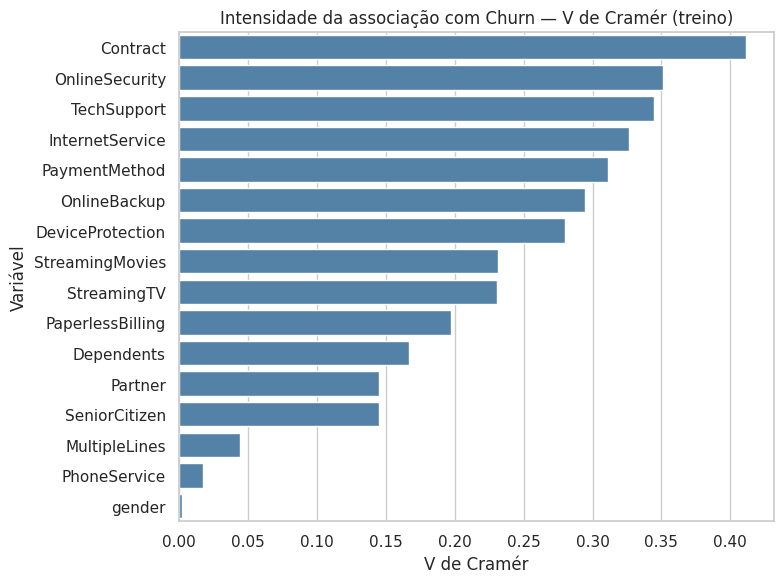

In [10]:
def cramers_v(x,y):
    tab=pd.crosstab(x,y)
    if min(tab.shape)<2:return np.nan
    chi,p,gl,esperado=chi2_contingency(tab)
    return np.sqrt(chi/(tab.values.sum()*min(tab.shape[0]-1,tab.shape[1]-1)))

linhas=[]
for variavel in COL_CAT_BASE:
    tab=pd.crosstab(eda[variavel],eda.Churn)
    chi,p,gl,esperado=chi2_contingency(tab)
    linhas.append({"Variável":variavel,"Qui-quadrado":chi,"GL":gl,"p":p,
                   "V de Cramér":cramers_v(eda[variavel],eda.Churn),
                   "Mínimo esperado":esperado.min()})
tabela_associacoes=pd.DataFrame(linhas).sort_values('V de Cramér',ascending=False).reset_index(drop=True)
tabela_associacoes['p_BH']=multipletests(tabela_associacoes.p,method='fdr_bh')[1]
tabela_associacoes['Significativo_BH_5%']=tabela_associacoes.p_BH<ALPHA
exibir_assoc=tabela_associacoes.copy()
for c in ['p','p_BH']:
    exibir_assoc[c]=exibir_assoc[c].map(lambda valor:f'{valor:.2e}')
display(exibir_assoc.round(4))
fig,ax=plt.subplots(figsize=(8,6))
sns.barplot(data=tabela_associacoes,x='V de Cramér',y='Variável',color='steelblue',ax=ax)
ax.set_title('Intensidade da associação com Churn — V de Cramér (treino)')
plt.tight_layout();plt.show()

**Interpretação:** o qui-quadrado avalia independência; V de Cramér resume a intensidade da associação sem indicar direção. P-valores pequenos não garantem efeitos grandes. Como são feitos múltiplos testes, os p-valores também são apresentados com correção de Benjamini–Hochberg (controle da taxa de falsas descobertas). A associação isolada de um atributo não equivale à sua importância condicional no modelo.

## 5. Redundância, segmentos e multicolinearidade

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2567,0.8294
MonthlyCharges,0.2567,1.0000,0.6540
TotalCharges,0.8294,0.6540,1.0000


MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,559,0
Yes,2685,0,2390


V(PhoneService,MultipleLines): 1.0


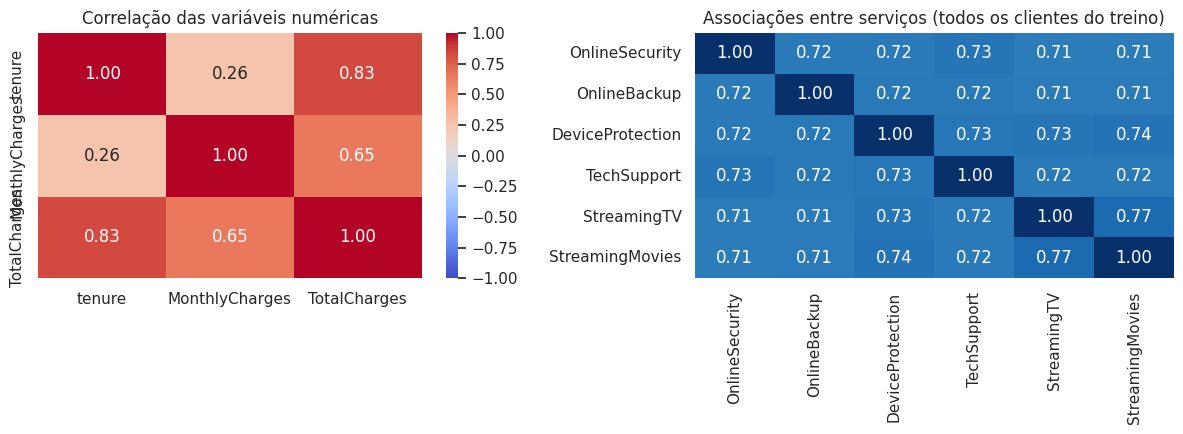

In [11]:
matriz_corr=eda[COL_NUM].corr()
display(matriz_corr.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
sns.heatmap(matriz_corr,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='coolwarm',ax=axes[0])
axes[0].set_title('Correlação das variáveis numéricas')
display(pd.crosstab(eda.PhoneService,eda.MultipleLines))
print('V(PhoneService,MultipleLines):',round(cramers_v(eda.PhoneService,eda.MultipleLines),4))
matriz_serv=pd.DataFrame(1.0,index=SERVICOS_INTERNET,columns=SERVICOS_INTERNET)
for i,a in enumerate(SERVICOS_INTERNET):
    for b in SERVICOS_INTERNET[i+1:]:
        matriz_serv.loc[a,b]=matriz_serv.loc[b,a]=cramers_v(eda[a],eda[b])
sns.heatmap(matriz_serv,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',ax=axes[1],cbar=False)
axes[1].set_title('Associações entre serviços (todos os clientes do treino)')
plt.tight_layout();plt.show()

In [12]:
# VIF com intercepto: diagnóstico exploratório APENAS entre as três numéricas.
from statsmodels.tools.tools import add_constant
X_vif=add_constant(eda[COL_NUM].fillna({"TotalCharges":0}))
tabela_vif=pd.DataFrame({"Variável":X_vif.columns,
                         "VIF":[variance_inflation_factor(X_vif.values,j)
                                for j in range(X_vif.shape[1])]})
display(tabela_vif.query("Variável != 'const'").round(4))

,Variável,VIF
1,tenure,5.9307
2,MonthlyCharges,3.2301
3,TotalCharges,9.6829


**Interpretação:** `TotalCharges` é fortemente relacionado a `tenure` e `MonthlyCharges`. VIF elevado indica dependência linear e dificulta interpretações individuais de coeficientes, mas não implica automaticamente pior previsão. VIF foi calculado apenas para as três variáveis numéricas, não para toda a matriz codificada. `PhoneService` e `MultipleLines` têm redundância estrutural; isso motiva cautela ao interpretar dummies. As análises de redundância não justificam excluir variáveis sem comparar o desempenho por validação cruzada.

In [13]:
# Avaliação descritiva dos serviços APENAS entre usuários de internet.
com_internet=eda.loc[eda.InternetService.ne('No')].copy()
sem_internet=eda.loc[eda.InternetService.eq('No')].copy()
print('Clientes do treino com internet:',len(com_internet),'| sem internet:',len(sem_internet))
linhas=[]
for variavel in SERVICOS_INTERNET:
    for cat,linha in taxa_categoria(com_internet,variavel).iterrows():
        linhas.append({"Serviço":variavel,"Status":cat,"Clientes":int(linha.Total),
                       "Cancelamentos":int(linha.Yes),"Churn (%)":linha['Taxa_Churn_%']})
display(pd.DataFrame(linhas))
print('Associação entre OnlineSecurity e TechSupport no segmento com internet:')
tab=pd.crosstab(com_internet.OnlineSecurity,com_internet.TechSupport)
display(tab)
chi,p,gl,esperados=chi2_contingency(tab)
print(f'Qui-quadrado={chi:.3f}; p={p:.3e}; V={cramers_v(com_internet.OnlineSecurity,com_internet.TechSupport):.3f}')

Clientes do treino com internet: 4420 | sem internet: 1214


,Serviço,Status,Clientes,Cancelamentos,Churn (%)
0,OnlineSecurity,No,2797,1173,41.94
1,OnlineSecurity,Yes,1623,234,14.42
2,OnlineBackup,No,2442,980,40.13
3,OnlineBackup,Yes,1978,427,21.59
4,DeviceProtection,No,2472,963,38.96
5,DeviceProtection,Yes,1948,444,22.79
6,TechSupport,No,2771,1157,41.75
7,TechSupport,Yes,1649,250,15.16
8,StreamingTV,No,2226,737,33.11
9,StreamingTV,Yes,2194,670,30.54


Associação entre OnlineSecurity e TechSupport no segmento com internet:


TechSupport,No,Yes
OnlineSecurity,,
No,2034,763
Yes,737,886


Qui-quadrado=326.364; p=5.952e-73; V=0.272


**Segmentação:** características e taxas diferentes entre usuários com e sem internet refletem populações com composições diferentes. A categoria compartilhada `No internet service` cria correlações artificiais entre os serviços opcionais quando o segmento não é controlado. Nenhuma dessas comparações identifica o efeito causal de contratar um serviço.

## 6. Pré-processamento seguro em pipelines

As variáveis quantitativas são imputadas (zero para `TotalCharges` ausente) e padronizadas; as variáveis categóricas são representadas por *one-hot encoding* com categoria de referência. O indicador `SeniorCitizen` é mantido como binário 0/1. `customerID` foi excluído por ser um identificador, sem significado preditivo generalizável. Todos os passos que estimam parâmetros são ajustados **apenas no fold de treinamento**.

In [14]:
colunas_numericas=COL_NUM.copy()
colunas_binarias=['SeniorCitizen']
colunas_categoricas=[c for c in X_train.select_dtypes(include=['object','category']).columns
                     if c not in colunas_binarias]

pipeline_numerico=Pipeline([
    ('imputacao_zero',SimpleImputer(strategy='constant',fill_value=0)),
    ('escala',StandardScaler())
])
pipeline_categorico=Pipeline([
    ('onehot',OneHotEncoder(handle_unknown='ignore',drop='first'))
])
preprocessador=ColumnTransformer([
    ('numericas',pipeline_numerico,colunas_numericas),
    ('categoricas',pipeline_categorico,colunas_categoricas),
    ('binarias','passthrough',colunas_binarias)
])

def modelo_com_preprocessamento(classificador,sampler=None):
    etapas=[('preprocessamento',clone(preprocessador))]
    if sampler is not None:
        etapas.append(('reamostragem',clone(sampler)))
    etapas.append(('classificador',clone(classificador)))
    return ImbPipeline(etapas) if sampler is not None else Pipeline(etapas)

modelo_logistico=modelo_com_preprocessamento(
    LogisticRegression(max_iter=2000,random_state=SEED)
)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
metricas={'accuracy':'accuracy','precision':'precision','recall':'recall',
          'f1':'f1','roc_auc':'roc_auc','average_precision':'average_precision'}
print('Colunas numéricas:',colunas_numericas)
print('Binárias:',colunas_binarias)
print('Categóricas:',len(colunas_categoricas),colunas_categoricas)

Colunas numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Binárias: ['SeniorCitizen']
Categóricas: 15 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 7. Modelos de referência: mesmo protocolo de validação

In [15]:
algoritmos={
    'Regressão logística':LogisticRegression(max_iter=2000,random_state=SEED),
    'Random Forest':RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1),
    'Gradient Boosting':GradientBoostingClassifier(random_state=SEED)
}
modelos_referencia={n:modelo_com_preprocessamento(est) for n,est in algoritmos.items()}

def avaliar_cv(nome,modelo,regime):
    r=cross_validate(modelo,X_train,y_train,cv=cv,scoring=metricas,
                     n_jobs=2,error_score='raise')
    out={'Modelo':nome,'Regime':regime}
    for m in metricas:
        out[m]=r['test_'+m].mean()
        out[m+'_dp']=r['test_'+m].std()
    return out

resultados_referencia=[avaliar_cv(n,modelo,'Sem reamostragem')
                       for n,modelo in modelos_referencia.items()]
tabela_referencia=pd.DataFrame(resultados_referencia)
display(tabela_referencia[['Modelo','accuracy','precision','recall','f1','roc_auc','average_precision']].round(4))

,Modelo,accuracy,precision,recall,f1,roc_auc,average_precision
0,Regressão logística,0.8028,0.6546,0.5445,0.5938,0.8462,0.6616
1,Random Forest,0.7891,0.6353,0.4843,0.5494,0.8260,0.6246
2,Gradient Boosting,0.8026,0.6664,0.5164,0.5815,0.8476,0.6648


A acurácia precisa ser comparada com a referência ingênua de classificar todo cliente como `No`, que atinge aproximadamente 73,5% mas apresenta **recall zero** para o cancelamento. Como a classe positiva representa cerca de 26,5%, as métricas **recall, F1, Average Precision e ROC-AUC** são fundamentais. A Average Precision deve ser analisada também em comparação com a prevalência de churn, que é o patamar de referência de uma ordenação aleatória.

## 8. Efeito do limiar de classificação (somente validação cruzada do treino)

,Limiar,Precisão,Recall,F1,Contato (%)
0,0.10,0.3999,0.9405,0.5612,62.4068
1,0.15,0.4380,0.9144,0.5923,55.3958
2,0.20,0.4755,0.8562,0.6114,47.7813
3,0.25,0.5096,0.8167,0.6276,42.5275
4,0.30,0.5421,0.7659,0.6349,37.4867
5,0.35,0.5700,0.7164,0.6349,33.3511
6,0.40,0.5938,0.6629,0.6264,29.6237
7,0.45,0.6237,0.6020,0.6127,25.6124
8,0.50,0.6543,0.5445,0.5944,22.0802
9,0.55,0.6859,0.4849,0.5682,18.7611


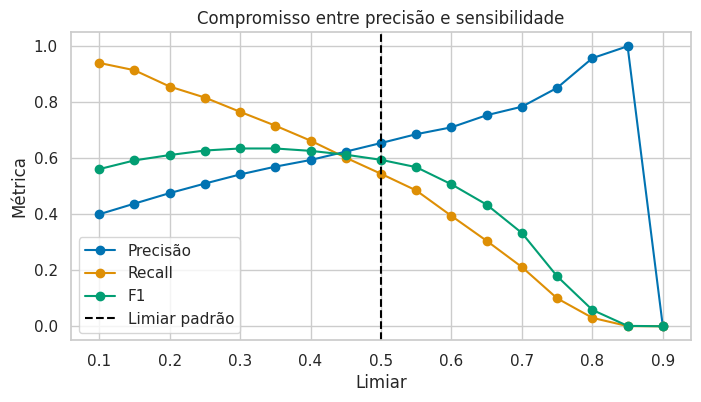

In [16]:
# Previsões fora do fold de ajuste, exclusivas do treinamento.
proba_oof_inicial=cross_val_predict(modelo_logistico,X_train,y_train,cv=cv,
                                    method='predict_proba',n_jobs=2)[:,1]
linhas=[]
for limiar in np.arange(.10,.91,.05):
    pred=(proba_oof_inicial>=limiar).astype(int)
    linhas.append({'Limiar':round(float(limiar),2),
                   'Precisão':precision_score(y_train,pred,zero_division=0),
                   'Recall':recall_score(y_train,pred,zero_division=0),
                   'F1':f1_score(y_train,pred,zero_division=0),
                   'Contato (%)':100*pred.mean()})
tabela_limiares=pd.DataFrame(linhas)
display(tabela_limiares.round(4))
fig,ax=plt.subplots(figsize=(8,4))
for col in ['Precisão','Recall','F1']:
    ax.plot(tabela_limiares.Limiar,tabela_limiares[col],marker='o',label=col)
ax.axvline(.5,color='black',linestyle='--',label='Limiar padrão')
ax.set(xlabel='Limiar',ylabel='Métrica',title='Compromisso entre precisão e sensibilidade')
ax.legend();plt.show()

Ao reduzir o limiar, mais clientes são classificados como potenciais cancelamentos, elevando geralmente o recall e o custo potencial de abordagens. Esta análise é **exploratória no treino**. O limiar final será fixado antes do uso do teste, com atenção à estratégia de negócio, e não escolhido pelo desempenho de teste.

## 9. Estratégias de balanceamento — requisito obrigatório

São comparadas três estratégias para **cada um dos mesmos três algoritmos**, nos **mesmos cinco folds**:

1. **Sem reamostragem:** distribuição original do treinamento.
2. **RandomUnderSampler:** reduz aleatoriamente a classe majoritária até equiparar os tamanhos das classes; pode perder informação.
3. **RandomOverSampler:** replica aleatoriamente exemplos da classe minoritária até equiparar os tamanhos; pode aumentar sobreajuste.

A reamostragem ocorre **após o pré-processamento, dentro do `imblearn.pipeline.Pipeline.fit`**, em cada fold de treinamento. O fold de validação conserva a distribuição natural. Não utilizamos SMOTE diretamente sobre dummies; o oversampling por replicação é apropriado ao desenho aqui utilizado.

In [17]:
regimes={
    'Sem reamostragem':None,
    'Undersampling':RandomUnderSampler(random_state=SEED),
    'Oversampling':RandomOverSampler(random_state=SEED)
}
resultados_balanceamento=list(resultados_referencia)
for regime,sampler in regimes.items():
    if sampler is None:continue
    for nome,algoritmo in algoritmos.items():
        modelo=modelo_com_preprocessamento(algoritmo,sampler=sampler)
        resultados_balanceamento.append(avaliar_cv(nome,modelo,regime))
tabela_balanceamento=pd.DataFrame(resultados_balanceamento)
cols_comparacao=['Modelo','Regime','precision','recall','f1','average_precision','roc_auc']
display(tabela_balanceamento[cols_comparacao].round(4).sort_values(['Modelo','Regime']))

,Modelo,Regime,precision,recall,f1,average_precision,roc_auc
8,Gradient Boosting,Oversampling,0.5255,0.7920,0.6318,0.6597,0.8471
2,Gradient Boosting,Sem reamostragem,0.6664,0.5164,0.5815,0.6648,0.8476
5,Gradient Boosting,Undersampling,0.5080,0.8080,0.6238,0.6587,0.8442
7,Random Forest,Oversampling,0.5953,0.5766,0.5855,0.6077,0.8222
1,Random Forest,Sem reamostragem,0.6353,0.4843,0.5494,0.6246,0.8260
4,Random Forest,Undersampling,0.5142,0.7732,0.6175,0.6251,0.8311
6,Regressão logística,Oversampling,0.5159,0.8007,0.6273,0.6588,0.8457
0,Regressão logística,Sem reamostragem,0.6546,0.5445,0.5938,0.6616,0.8462
3,Regressão logística,Undersampling,0.5166,0.8020,0.6283,0.6615,0.8462


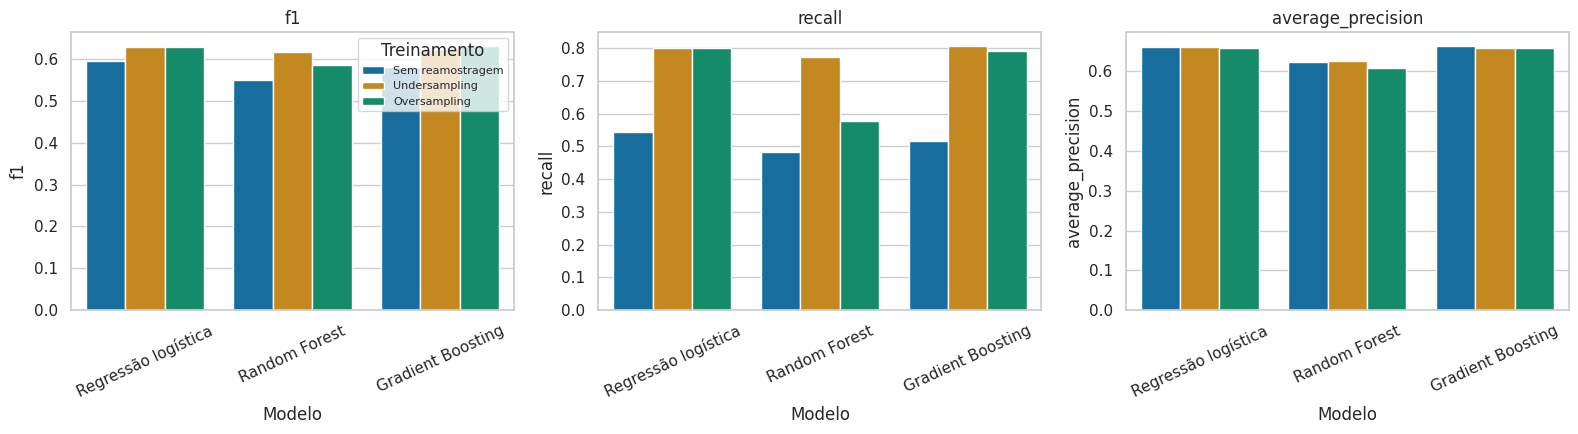

Maiores F1 e AP entre as estratégias analisadas:


,Modelo,Regime,precision,recall,f1,average_precision,roc_auc
8,Gradient Boosting,Oversampling,0.5255,0.7920,0.6318,0.6597,0.8471
3,Regressão logística,Undersampling,0.5166,0.8020,0.6283,0.6615,0.8462
6,Regressão logística,Oversampling,0.5159,0.8007,0.6273,0.6588,0.8457
5,Gradient Boosting,Undersampling,0.5080,0.8080,0.6238,0.6587,0.8442


,Modelo,Regime,precision,recall,f1,average_precision,roc_auc
2,Gradient Boosting,Sem reamostragem,0.6664,0.5164,0.5815,0.6648,0.8476
0,Regressão logística,Sem reamostragem,0.6546,0.5445,0.5938,0.6616,0.8462
3,Regressão logística,Undersampling,0.5166,0.8020,0.6283,0.6615,0.8462
8,Gradient Boosting,Oversampling,0.5255,0.7920,0.6318,0.6597,0.8471


In [18]:
# Mesmos algoritmos e folds; gráfico focado na tarefa de cancelamento.
fig,axes=plt.subplots(1,3,figsize=(16,4.5),sharey=False)
for ax,metrica in zip(axes,['f1','recall','average_precision']):
    sns.barplot(data=tabela_balanceamento,x='Modelo',y=metrica,hue='Regime',ax=ax)
    ax.set_title(metrica)
    ax.tick_params(axis='x',rotation=25)
    if ax!=axes[0]:ax.get_legend().remove()
axes[0].legend(title='Treinamento',loc='best',fontsize=8)
plt.tight_layout();plt.show()
print('Maiores F1 e AP entre as estratégias analisadas:')
display(tabela_balanceamento.nlargest(4,'f1')[cols_comparacao].round(4))
display(tabela_balanceamento.nlargest(4,'average_precision')[cols_comparacao].round(4))

**Discussão crítica:** uma estratégia pode melhorar a sensibilidade e simultaneamente reduzir a precisão. A **Average Precision** mede a capacidade de ordenar os casos positivos e não deve ser confundida com a precisão num único limiar. A comparação dos modelos deve considerar tanto o objetivo de detectar mais cancelamentos quanto o custo dos falsos alarmes. A eventual melhoria de F1 não elimina a perda de dados na subamostragem nem o risco de sobreajuste na sobreamostragem. `class_weight='balanced'` é outra estratégia, baseada em ponderação da função de perda, **não é reamostragem**.

## 10. Ajuste de hiperparâmetros e ponderação de classes

In [19]:
parametros={
    'classificador__C':[0.01,0.1,1,10,100],
    'classificador__class_weight':[None,'balanced']
}
grid_logistico=GridSearchCV(modelo_logistico,param_grid=parametros,
                             scoring='f1',cv=cv,n_jobs=2,refit=True,
                             error_score='raise')
grid_logistico.fit(X_train,y_train)
modelo_final=grid_logistico.best_estimator_
print('Melhores parâmetros:',grid_logistico.best_params_)
print('F1 de seleção na CV:',round(grid_logistico.best_score_,4))
resultados_grade=pd.DataFrame(grid_logistico.cv_results_)
display(resultados_grade[['param_classificador__C','param_classificador__class_weight',
                          'mean_test_score','std_test_score','rank_test_score']]
        .sort_values('rank_test_score').head(10).round(4))

Melhores parâmetros: {'classificador__C': 0.1, 'classificador__class_weight': 'balanced'}
F1 de seleção na CV: 0.6299


,param_classificador__C,param_classificador__class_weight,mean_test_score,std_test_score,rank_test_score
3,0.10,balanced,0.6299,0.0218,1
5,1.00,balanced,0.6296,0.0226,2
1,0.01,balanced,0.6277,0.0200,3
7,10.00,balanced,0.6277,0.0245,4
9,100.00,balanced,0.6272,0.0233,5
6,10.00,None,0.5978,0.0300,6
8,100.00,None,0.5974,0.0288,7
4,1.00,None,0.5938,0.0303,8
2,0.10,None,0.5892,0.0283,9
0,0.01,None,0.5638,0.0274,10


A regressão logística é priorizada pela interpretabilidade dos coeficientes e pelo equilíbrio entre precisão e sensibilidade. O parâmetro `C` controla a regularização L2 (quanto menor, maior a regularização). Pesos balanceados alteram a função de perda sem duplicar ou excluir clientes. A seleção pelo maior F1 médio da mesma CV pode ter otimismo; por isso, na próxima etapa utilizamos **validação cruzada aninhada** para uma estimativa complementar.

### 10.1. Ajuste comparativo de hiperparâmetros — modelos baseados em árvores

In [20]:
# Buscas pequenas e reprodutíveis. Usar APENAS treino e os mesmos cinco folds.
grades_arvores = {
    'Random Forest': {
        'classificador__min_samples_leaf': [1, 5],
        'classificador__class_weight': [None, 'balanced']
    },
    'Gradient Boosting': {
        'classificador__n_estimators': [100, 150],
        'classificador__learning_rate': [0.05, 0.1]
    }
}
resultados_tuning=[]
melhores_arvores={}
for nome,grid_param in grades_arvores.items():
    busca=GridSearchCV(modelos_referencia[nome],grid_param,scoring='f1',
                        cv=cv,n_jobs=2,refit=True,error_score='raise')
    busca.fit(X_train,y_train)
    melhores_arvores[nome]=busca.best_estimator_
    resultados_tuning.append({'Modelo':nome,'F1 (CV seleção)':busca.best_score_,
                               'Melhores parâmetros':str(busca.best_params_)})
resultados_tuning.append({'Modelo':'Regressão logística',
                          'F1 (CV seleção)':grid_logistico.best_score_,
                          'Melhores parâmetros':str(grid_logistico.best_params_)})
display(pd.DataFrame(resultados_tuning).sort_values('F1 (CV seleção)',ascending=False).to_string(index=False))
modelos_ajustados={'Regressão logística':modelo_final,**melhores_arvores}
comparacao_ajustados=[avaliar_cv(nome,modelo,'Tuning por CV')
                     for nome,modelo in modelos_ajustados.items()]
print('Métricas por CV das versões selecionadas (exploratórias, após escolha dos parâmetros):')
display(pd.DataFrame(comparacao_ajustados)[['Modelo','precision','recall','f1',
                                          'roc_auc','average_precision']].round(4))

"             Modelo  F1 (CV seleção)                                                               Melhores parâmetros\n      Random Forest         0.635785 {'classificador__class_weight': 'balanced', 'classificador__min_samples_leaf': 5}\nRegressão logística         0.629911              {'classificador__C': 0.1, 'classificador__class_weight': 'balanced'}\n  Gradient Boosting         0.582711        {'classificador__learning_rate': 0.05, 'classificador__n_estimators': 150}"

Métricas por CV das versões selecionadas (exploratórias, após escolha dos parâmetros):


,Modelo,precision,recall,f1,roc_auc,average_precision
0,Regressão logística,0.5211,0.7967,0.6299,0.8455,0.6603
1,Random Forest,0.5642,0.7284,0.6358,0.8442,0.6574
2,Gradient Boosting,0.6713,0.5157,0.5827,0.8487,0.6670


**Resposta à pergunta “qual é o melhor classificador?” — depende da métrica e do objetivo.**

Na busca exploratória por validação cruzada, a **Random Forest ajustada** obteve o maior F1 entre os três algoritmos ajustados (**0,6358**), contra **0,6299** da regressão logística. Entretanto, a **regressão logística ajustada apresentou maior recall** (**0,7967**, contra **0,7284** da Random Forest), uma vantagem para identificar mais clientes em risco. O **Gradient Boosting ajustado** apresentou a maior **Average Precision (0,6670)** e **ROC-AUC (0,8487)**, mesmo com menor F1 (**0,5827**) no limiar padrão.

Essas pontuações foram obtidas nos folds também usados para selecionar hiperparâmetros, portanto são estimativas **de seleção** e podem ser otimistas. A opção pela regressão logística final é uma **decisão operacional justificada por recall e interpretabilidade**, não uma afirmação de superioridade universal nem de diferença estatisticamente comprovada. A validação aninhada abaixo oferece uma estimativa adicional mais rigorosa para a estratégia escolhida.

**Comparação:** os três algoritmos tiveram pelo menos uma busca de hiperparâmetros feita por validação cruzada. Essas são pontuações **de seleção**, potencialmente otimistas por escolher o máximo entre combinações; a validação aninhada seguinte é a referência mais cautelosa para a regressão logística final. A escolha final privilegia também interpretabilidade e sensibilidade, não apenas diferenças pequenas de F1 entre grades de tamanhos distintos.

### 10.2. Avaliação de generalização por validação cruzada aninhada

In [21]:
cv_externo=StratifiedKFold(n_splits=5,shuffle=True,random_state=123)
cv_interno=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
grid_aninhado=GridSearchCV(modelo_logistico,param_grid=parametros,
                           scoring='f1',cv=cv_interno,n_jobs=1,refit=True)
nested=cross_validate(grid_aninhado,X_train,y_train,cv=cv_externo,
                      scoring=metricas,n_jobs=2,error_score='raise')
resumo_aninhado=pd.DataFrame({
    'Métrica':list(metricas),
    'Média':[nested['test_'+m].mean() for m in metricas],
    'DP':[nested['test_'+m].std() for m in metricas]
})
display(resumo_aninhado.round(4))

,Métrica,Média,DP
0,accuracy,0.7531,0.0167
1,precision,0.5232,0.0218
2,recall,0.8000,0.0265
3,f1,0.6325,0.0212
4,roc_auc,0.8452,0.0161
5,average_precision,0.6609,0.0422


### 10.3. Investigação de seleção de variáveis: sem `TotalCharges`

In [22]:
# Trocar o ColumnTransformer inteiro, não tentar "preprocessamento__numericas__columns".
pre_sem_total=ColumnTransformer([
    ('numericas',clone(pipeline_numerico),['tenure','MonthlyCharges']),
    ('categoricas',clone(pipeline_categorico),colunas_categoricas),
    ('binarias','passthrough',colunas_binarias)
])
modelo_sem_total=clone(modelo_final)
modelo_sem_total.set_params(preprocessamento=pre_sem_total)
X_train_sem_total=X_train.drop(columns=['TotalCharges'])
comparacao_atributos=[]
for nome,est,X_sub in [('Com TotalCharges',modelo_final,X_train),
                       ('Sem TotalCharges',modelo_sem_total,X_train_sem_total)]:
    r=cross_validate(est,X_sub,y_train,cv=cv,scoring=metricas,n_jobs=2)
    comparacao_atributos.append({'Modelo':nome,**{m:r['test_'+m].mean() for m in metricas}})
display(pd.DataFrame(comparacao_atributos).round(4))
# Coeficientes padronizados: comparação descritiva entre modelos ajustados no treino.
modelo_sem_total.fit(X_train_sem_total,y_train)
def coef_numericos(modelo):
    nomes=modelo.named_steps['preprocessamento'].get_feature_names_out()
    betas=modelo.named_steps['classificador'].coef_.ravel()
    return pd.Series(betas,index=nomes)
comparacao_coef=pd.DataFrame({
    'Com TotalCharges':coef_numericos(modelo_final),
    'Sem TotalCharges':coef_numericos(modelo_sem_total)
}).loc[lambda t:t.index.str.contains('numericas')]
display(comparacao_coef.round(4))

,Modelo,accuracy,precision,recall,f1,roc_auc,average_precision
0,Com TotalCharges,0.7517,0.5211,0.7967,0.6299,0.8455,0.6603
1,Sem TotalCharges,0.7538,0.5239,0.7933,0.6309,0.8447,0.6593


,Com TotalCharges,Sem TotalCharges
numericas__MonthlyCharges,0.1593,0.2256
numericas__TotalCharges,0.2962,NaN
numericas__tenure,-1.0105,-0.7754


A mudança dos coeficientes após remover `TotalCharges` é compatível com dependência entre preditores, mas **não demonstra sozinha** que a multicolinearidade seja a única causa: regularização e diferenças de ajuste também importam. A comparação de modelos com e sem a variável, nos mesmos folds, avalia se a exclusão traz benefício preditivo. Para preservar a avaliação original, esta análise é considerada exploratória e não modifica automaticamente a estratégia final selecionada.

### 10.4. Decisão de classificação pré-especificada

In [23]:
# Apenas dados de treinamento; o teste segue reservado.
prob_oof_final=cross_val_predict(clone(modelo_final),X_train,y_train,cv=cv,
                                method='predict_proba',n_jobs=2)[:,1]
limiares_modelo_final=[0.30,0.40,0.50,0.60]
limiar_final=0.50  # escolha operacional antes da avaliação em teste
linhas=[]
for limiar in limiares_modelo_final:
    pred=(prob_oof_final>=limiar).astype(int)
    linhas.append({'Limiar':limiar,'Precision':precision_score(y_train,pred),
                   'Recall':recall_score(y_train,pred),'F1':f1_score(y_train,pred),
                   'Abordagens (%)':100*pred.mean()})
display(pd.DataFrame(linhas).round(4))
print('Limiar final pré-definido:',limiar_final)

,Limiar,Precision,Recall,F1,Abordagens (%)
0,0.3,0.4237,0.9271,0.5816,58.0582
1,0.4,0.4732,0.8629,0.6112,48.3848
2,0.5,0.5210,0.7967,0.6300,40.5751
3,0.6,0.5734,0.7084,0.6338,32.7831


Limiar final pré-definido: 0.5


**Decisão:** utilizamos o classificador logístico regularizado e o limiar de 0,50, escolhido antes da avaliação independente em teste. Com ponderação de classes, o limiar 0,50 não deve ser entendido como uma estimativa de risco individual automaticamente calibrada. Para priorização e descontos, é importante analisar custos e, se necessário, calibrar probabilidades utilizando apenas dados de treinamento. Resultados de validação cruzada do modelo com hiperparâmetros previamente selecionados são **exploratórios**, enquanto a validação aninhada oferece estimativa menos sujeita a viés de seleção.

## 11. Interpretação do modelo — exclusivamente com dados de treinamento

In [24]:
nomes_transformados=modelo_final.named_steps['preprocessamento'].get_feature_names_out()
betas=modelo_final.named_steps['classificador'].coef_[0]
tabela_coeficientes=pd.DataFrame({
    'Variável transformada':nomes_transformados,
    'Coeficiente':betas,
    'Odds ratio':np.exp(betas)
}).sort_values('Coeficiente',ascending=False)
display(tabela_coeficientes.round(4))

,Variável transformada,Coeficiente,Odds ratio
9,categoricas__InternetService_Fiber optic,0.6567,1.9283
27,categoricas__PaymentMethod_Electronic check,0.3929,1.4812
25,categoricas__PaperlessBilling_Yes,0.3317,1.3934
2,numericas__TotalCharges,0.2962,1.3447
7,categoricas__MultipleLines_No phone service,0.2358,1.2659
8,categoricas__MultipleLines_Yes,0.2107,1.2345
22,categoricas__StreamingMovies_Yes,0.1963,1.2168
20,categoricas__StreamingTV_Yes,0.1757,1.1921
29,binarias__SeniorCitizen,0.1632,1.1773
1,numericas__MonthlyCharges,0.1593,1.1727


Na regressão logística, `exp(coeficiente)` corresponde à **odds ratio condicional** de uma mudança unitária no preditor transformado, mantidas as demais variáveis constantes. Para numéricas padronizadas, a unidade é **um desvio-padrão**; para dummies, a comparação é com a categoria de referência (primeira categoria excluída pelo encoder). Coeficientes não mostram causalidade; a correlação entre atributos e a categoria estrutural repetida `No internet service` exigem cautela. Com `class_weight='balanced'`, o intercepto e as probabilidades previstas também dependem da ponderação adotada.

In [25]:
# Importância em uma subamostra de validação obtida SOMENTE dentro do treino.
# Comparação da importância nas três famílias de algoritmos com o mesmo split interno.
X_i_tr,X_i_val,y_i_tr,y_i_val=train_test_split(
    X_train,y_train,test_size=.25,stratify=y_train,random_state=2026)
modelos_interpretacao={
    'Regressão logística ajustada':clone(modelo_final),
    'Random Forest':clone(modelos_referencia['Random Forest']),
    'Gradient Boosting':clone(modelos_referencia['Gradient Boosting'])
}
importancias=[]
for nome,mod in modelos_interpretacao.items():
    mod.fit(X_i_tr,y_i_tr)
    imp=permutation_importance(mod,X_i_val,y_i_val,scoring='roc_auc',
                               n_repeats=5,random_state=SEED,n_jobs=2)
    for variavel,media,dp in zip(X_train.columns,imp.importances_mean,imp.importances_std):
        importancias.append({'Modelo':nome,'Variável':variavel,
                             'Importância média':media,'DP':dp})
tabela_importancias=pd.DataFrame(importancias)
for nome in modelos_interpretacao:
    print('\n'+nome+' — principais variáveis')
    display(tabela_importancias.query('Modelo == @nome')
            .sort_values('Importância média',ascending=False).head(10).round(4))


Regressão logística ajustada — principais variáveis


,Modelo,Variável,Importância média,DP
4,Regressão logística ajustada,tenure,0.1215,0.0076
14,Regressão logística ajustada,Contract,0.0246,0.0025
7,Regressão logística ajustada,InternetService,0.0152,0.0020
18,Regressão logística ajustada,TotalCharges,0.0058,0.0007
8,Regressão logística ajustada,OnlineSecurity,0.0042,0.0016
15,Regressão logística ajustada,PaperlessBilling,0.0041,0.0009
17,Regressão logística ajustada,MonthlyCharges,0.0030,0.0014
16,Regressão logística ajustada,PaymentMethod,0.0024,0.0018
11,Regressão logística ajustada,TechSupport,0.0013,0.0024
13,Regressão logística ajustada,StreamingMovies,0.0012,0.0004



Random Forest — principais variáveis


,Modelo,Variável,Importância média,DP
23,Random Forest,tenure,0.0275,0.0083
33,Random Forest,Contract,0.0182,0.0012
37,Random Forest,TotalCharges,0.0090,0.0032
26,Random Forest,InternetService,0.0087,0.0027
34,Random Forest,PaperlessBilling,0.0037,0.0035
20,Random Forest,SeniorCitizen,0.0034,0.0008
35,Random Forest,PaymentMethod,0.0021,0.0034
30,Random Forest,TechSupport,0.0021,0.0030
27,Random Forest,OnlineSecurity,0.0011,0.0011
24,Random Forest,PhoneService,-0.0011,0.0003



Gradient Boosting — principais variáveis


,Modelo,Variável,Importância média,DP
42,Gradient Boosting,tenure,0.0722,0.0052
52,Gradient Boosting,Contract,0.0378,0.0030
55,Gradient Boosting,MonthlyCharges,0.0216,0.0049
45,Gradient Boosting,InternetService,0.0207,0.0024
49,Gradient Boosting,TechSupport,0.0201,0.0044
53,Gradient Boosting,PaperlessBilling,0.0034,0.0012
54,Gradient Boosting,PaymentMethod,0.0030,0.0014
46,Gradient Boosting,OnlineSecurity,0.0025,0.0014
56,Gradient Boosting,TotalCharges,0.0022,0.0024
50,Gradient Boosting,StreamingTV,0.0020,0.0003


**Importância por permutação:** cada atributo é embaralhado no conjunto de **validação interno** para observar a queda média do ROC-AUC. A avaliação é exploratória e não altera a escolha do modelo; diferentemente da importância calculada no próprio conjunto ajustado, reduz o viés de reavaliação sobre os mesmos registros. Variáveis correlacionadas podem dividir a importância, de modo que uma importância individual pequena não demonstra inutilidade. Confronte as variáveis relevantes para regressão logística, Random Forest e Gradient Boosting: a ordem pode mudar entre algoritmos sem invalidar as associações exploratórias.

## 12. Avaliação final independente — única utilização do conjunto de teste

**Protocolo:** a estratégia e o limiar foram fixados usando apenas treinamento/validação cruzada. Não modificar hiperparâmetros, atributos ou limiar em função dos resultados a seguir. O teste mantém a proporção original das classes e não passa por reamostragem.

,Métrica,Valor
0,Acurácia,0.7431
1,Precisão,0.5105
2,Recall/sensibilidade,0.7834
3,F1,0.6181
4,ROC-AUC,0.8413
5,Average Precision,0.6344


Matriz de confusão (linhas=classe real, colunas=previsão; 0=permanece, 1=cancela):
[[754 281]
 [ 81 293]]


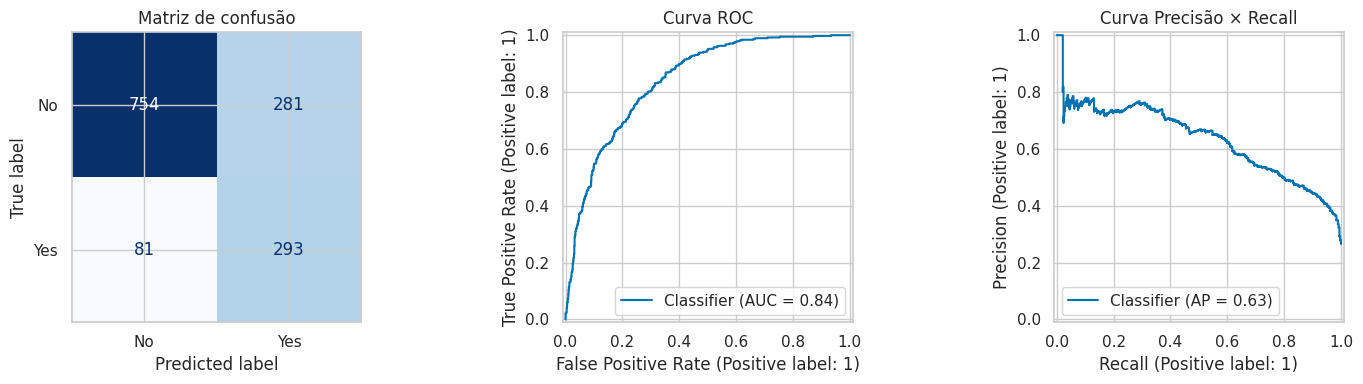

In [26]:
# Esta é a única seção em que X_test e y_test são usados para avaliação.
prob_teste=modelo_final.predict_proba(X_test)[:,1]
pred_teste=(prob_teste>=limiar_final).astype(int)
metricas_teste={
    'Acurácia':accuracy_score(y_test,pred_teste),
    'Precisão':precision_score(y_test,pred_teste),
    'Recall/sensibilidade':recall_score(y_test,pred_teste),
    'F1':f1_score(y_test,pred_teste),
    'ROC-AUC':roc_auc_score(y_test,prob_teste),
    'Average Precision':average_precision_score(y_test,prob_teste)
}
display(pd.DataFrame({'Métrica':list(metricas_teste),
                      'Valor':list(metricas_teste.values())}).round(4))
matriz_final=confusion_matrix(y_test,pred_teste,labels=[0,1])
print('Matriz de confusão (linhas=classe real, colunas=previsão; 0=permanece, 1=cancela):')
print(matriz_final)
fig,axes=plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay(matriz_final,display_labels=['No','Yes']).plot(ax=axes[0],colorbar=False,cmap='Blues')
RocCurveDisplay.from_predictions(y_test,prob_teste,ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test,prob_teste,ax=axes[2])
axes[0].set_title('Matriz de confusão')
axes[1].set_title('Curva ROC')
axes[2].set_title('Curva Precisão × Recall')
plt.tight_layout();plt.show()

### 12.1. Capacidade operacional: contato com apenas 10% dos clientes

In [27]:
# Selecionar os 10% maiores escores, SEM usar o rótulo para escolher os clientes.
# A proporção real de cancelamentos é usada apenas para avaliar o resultado final.
n_test=len(y_test)
k=int(np.ceil(.10*n_test))
ordem=np.argsort(-prob_teste,kind='stable')
top10=ordem[:k]
y_test_array=y_test.to_numpy()
positivos_top10=int(y_test_array[top10].sum())
total_positivos=int(y_test_array.sum())
recall_top10=positivos_top10/total_positivos
precision_top10=positivos_top10/k
lift_top10=precision_top10/y_test.mean()
# Benchmark aleatório: 10% da fração de cancelamentos esperados.
resultado_top10=pd.DataFrame([{
    'Clientes de teste':n_test,
    'Contatos (10%)':k,
    'Cancelamentos existentes':total_positivos,
    'Cancelamentos no top 10%':positivos_top10,
    'Recall@10%':recall_top10,
    'Precisão@10%':precision_top10,
    'Lift@10%':lift_top10
}])
display(resultado_top10.round(4))
print(f'Com apenas {k} contatos, seriam identificados {positivos_top10} de '
      f'{total_positivos} cancelamentos ({100*recall_top10:.2f}%).')
print(f'Ao acaso, 10% dos clientes concentrariam em média 10% dos cancelamentos; '
      f'nesse recorte, lift={lift_top10:.2f}x.')

,Clientes de teste,Contatos (10%),Cancelamentos existentes,Cancelamentos no top 10%,Recall@10%,Precisão@10%,Lift@10%
0,1409,141,374,108,0.2888,0.766,2.8857


Com apenas 141 contatos, seriam identificados 108 de 374 cancelamentos (28.88%).
Ao acaso, 10% dos clientes concentrariam em média 10% dos cancelamentos; nesse recorte, lift=2.89x.


O indicador **Recall@10%** responde diretamente à questão proposta: qual parcela de todos os cancelamentos está entre os 10% de clientes com maiores escores de risco? **Precisão@10%** mede a fração dos contatados que realmente cancelariam; **Lift@10%** compara a concentração de cancelamentos com a prevalência da base. Essas métricas avaliam priorização por ranking, independentemente do limiar binário 0,50. O cálculo acima usa apenas a avaliação final já reservada; não é empregado para retreinar ou escolher um novo modelo.

## 13. Discussão de resultados, aplicação empresarial e limites causais

In [28]:
# Síntese gerada a partir das saídas reais, sem valores desatualizados no texto.
tn,fp,fn,tp=matriz_final.ravel()
melhor_f1=tabela_balanceamento.loc[tabela_balanceamento.f1.idxmax()]
melhor_ap=tabela_balanceamento.loc[tabela_balanceamento.average_precision.idxmax()]
print('SÍNTESE REPRODUZÍVEL')
print(f'- Modelo final: regressão logística, parâmetros {grid_logistico.best_params_}, limiar={limiar_final:.2f}.')
print(f'- Teste: TP={tp}, FP={fp}, FN={fn}, TN={tn}.')
print(f'- F1={metricas_teste["F1"]:.4f}; recall={metricas_teste["Recall/sensibilidade"]:.4f}; '
      f'precisão={metricas_teste["Precisão"]:.4f}; ROC-AUC={metricas_teste["ROC-AUC"]:.4f}; '
      f'AP={metricas_teste["Average Precision"]:.4f}.')
print(f'- Contato em 10%: {positivos_top10}/{total_positivos} cancelamentos; '
      f'Recall@10%={recall_top10:.4f}; Lift@10%={lift_top10:.2f}x.')
print(f'- Maior F1 na comparação simples: {melhor_f1.Modelo} / {melhor_f1.Regime} '
      f'(F1={melhor_f1.f1:.4f}).')
print(f'- Maior AP na comparação simples: {melhor_ap.Modelo} / {melhor_ap.Regime} '
      f'(AP={melhor_ap.average_precision:.4f}).')

SÍNTESE REPRODUZÍVEL
- Modelo final: regressão logística, parâmetros {'classificador__C': 0.1, 'classificador__class_weight': 'balanced'}, limiar=0.50.
- Teste: TP=293, FP=281, FN=81, TN=754.
- F1=0.6181; recall=0.7834; precisão=0.5105; ROC-AUC=0.8413; AP=0.6344.
- Contato em 10%: 108/374 cancelamentos; Recall@10%=0.2888; Lift@10%=2.89x.
- Maior F1 na comparação simples: Gradient Boosting / Oversampling (F1=0.6318).
- Maior AP na comparação simples: Gradient Boosting / Sem reamostragem (AP=0.6648).


### 13.1. Interpretação empresarial

Os resultados do treinamento apontam associações entre churn, tempo de permanência, modalidade do contrato, serviço de internet e outras características de cobrança/atendimento. A capacidade de discriminação do modelo pode ajudar a **priorizar** abordagens, mas um cliente classificado como provável cancelamento não necessariamente cancelaria, e prever um risco não equivale a evitá-lo.

Uma estratégia **a ser testada** consiste em oferecer incentivos progressivos para migração voluntária de contratos mensais para contratos anuais ou bienais. Outra hipótese é experimentar benefícios, atendimento proativo ou ajustes de preço para perfis específicos. A empresa deveria considerar o **custo de contato**, o **custo do incentivo**, a margem e o efeito real de retenção; uma campanha com muitos falsos positivos pode ser cara.

### 13.2. Associação não é causalidade

Contratos longos apresentam menor churn observado, mas clientes já satisfeitos podem ter maior propensão a contratá-los. Para avaliar o **efeito causal de uma oferta de desconto**, sugere-se um **teste A/B com alocação aleatória** de clientes elegíveis, acompanhamento temporal e análise da diferença de cancelamentos (além do custo da campanha). Um experimento assim estima o efeito da **oferta**, não necessariamente o efeito isolado de ter um contrato mais longo.

### 13.3. Limitações

- Dados observacionais e transversais, sem histórico temporal de satisfação, tickets de suporte ou causas declaradas do churn.
- Desbalanceamento, trade-off entre recall e precisão, e risco operacional de falsos positivos.
- Relações estruturais e multicolinearidade dificultam interpretação isolada dos coeficientes.
- A reamostragem pode perder informações ou repetir registros; pesos balanceados podem alterar a calibração das probabilidades.
- Comparações na CV têm incerteza amostral e não comprovam estabilidade em outros períodos ou operadoras.
- Importâncias por permutação de atributos correlacionados não representam efeitos independentes nem causais.

### 13.4. Trabalhos futuros

Validar o modelo em período posterior e/ou empresa distinta; calibrar probabilidades sem utilizar o teste; definir o limiar e o orçamento de contatos segundo uma matriz de custos; incorporar custos operacionais, confiança nos rótulos e efeitos de campanha; analisar fairness e heterogeneidade dos efeitos; conduzir testes A/B das ofertas de retenção.

## 14. Conclusão

Foi implementado um fluxo reprodutível de Ciência de Dados para Telco Customer Churn, com auditoria da base, separação estratificada, análise exploratória e inferencial exclusivamente no treino, investigação de redundâncias, pré-processamento incorporado aos pipelines e comparação de três modelos. A avaliação incluiu comparação do limiar, ponderação por classe, **subamostragem e sobreamostragem** sob o mesmo protocolo, otimização por validação cruzada e uma estimativa por validação aninhada.

A avaliação independente apresenta precisão, sensibilidade, F1, ROC-AUC, Average Precision, matriz de confusão e **Recall@10%**, possibilitando discutir cenários em que a empresa consegue contatar apenas uma fração dos clientes. As análises de coeficientes, importância por permutação e multicolinearidade ajudam a interpretar o comportamento do classificador, com as cautelas apropriadas.

A escolha de uma estratégia de retenção deve combinar desempenho preditivo, custos e capacidade operacional. Os padrões encontrados são **associações observacionais**; sua transformação em políticas eficazes depende de experimentos e monitoramento. O notebook não utiliza os resultados de teste para refazer o modelo.